# Marketing A/B test

This is a portfolio exercise using the public [Marketing A/B Testing dataset on Kaggle](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing), shared by faviovaz. It is not an experiment conducted by the author. The file labels users as `ad` or `psa` and records whether they converted.

## Question and hypotheses

Does the conversion rate differ between the ad and public service announcement (PSA) groups? The primary metric is the proportion of users who converted.

- **Null hypothesis:** the population conversion rates are equal (p_ad = p_psa).
- **Alternative hypothesis:** the population conversion rates differ (p_ad != p_psa).
- We use a two-sided test and a 5% significance level for this exercise. The source CSV does not establish a prespecified analysis plan. Statistical significance alone is not a launch criterion.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

path = Path("data/marketing_AB.csv")
if not path.exists():
    path = Path("../data/marketing_AB.csv")
if not path.exists():
    raise FileNotFoundError("Place marketing_AB.csv in data/")
df = pd.read_csv(path)
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## Data and design checks

Check required fields, missing values, group labels, boolean outcomes and duplicate user IDs. The CSV contains one row per user according to the unique ID check; this alone does not establish that observations or assignments are independent.

In [2]:
required = {"user id", "test group", "converted"}
if required - set(df.columns):
    raise ValueError(f"Missing columns: {required - set(df.columns)}")
if df[list(required)].isna().any().any():
    raise ValueError("Missing analysis values")
if df["user id"].duplicated().any():
    raise ValueError("Duplicate user IDs")
if set(df["test group"].unique()) != {"ad", "psa"}:
    raise ValueError("Expected ad and psa groups")
if not pd.api.types.is_bool_dtype(df["converted"]):
    raise ValueError("Conversion values must be True or False")
print(f"Rows: {len(df):,}; unique users: {df['user id'].nunique():,}")
display(df.isna().sum().to_frame("missing"))

Rows: 588,101; unique users: 588,101


,missing
Unnamed: 0,0
user id,0
test group,0
converted,0
total ads,0
most ads day,0
most ads hour,0


In [3]:
group_sizes = df["test group"].value_counts().rename("users").to_frame()
group_sizes["share"] = group_sizes["users"] / len(df)
display(group_sizes.style.format({"users": "{:,.0f}", "share": "{:.2%}"}))
print(f"Ad-to-PSA size ratio: {group_sizes.loc['ad', 'users'] / group_sizes.loc['psa', 'users']:.1f}:1")

,users,share
test group,,
ad,"564,577",96.00%
psa,"23,524",4.00%


Ad-to-PSA size ratio: 24.0:1


The ad group is much larger than the PSA group. Unequal allocation can be intentional; without the planned allocation ratio, a sample-ratio mismatch test cannot be interpreted. Assignment method, eligibility, dates, exposure and conversion window are not verified by this CSV. The large number of conversions and non-conversions in both groups supports the normal approximation, conditional on independent observations.

## Conversion rates

Conversion rate is converted users divided by users in each group. Absolute difference is ad minus PSA; relative lift divides the difference by the PSA rate.

In [4]:
summary = (df.groupby("test group")["converted"]
           .agg(users="size", conversions="sum", conversion_rate="mean")
           .loc[["psa", "ad"]])
display(summary.style.format({"users": "{:,.0f}", "conversions": "{:,.0f}", "conversion_rate": "{:.3%}"}))
p_control = summary.loc["psa", "conversion_rate"]
p_ad = summary.loc["ad", "conversion_rate"]
if p_control == 0:
    raise ValueError("Relative lift is undefined when PSA conversion is zero")
difference = p_ad - p_control
print(f"Absolute difference: {difference * 100:.3f} percentage points")
print(f"Relative lift: {difference / p_control:.2%}")

,users,conversions,conversion_rate
test group,,,
psa,"23,524",420,1.785%
ad,"564,577","14,423",2.555%


Absolute difference: 0.769 percentage points
Relative lift: 43.09%


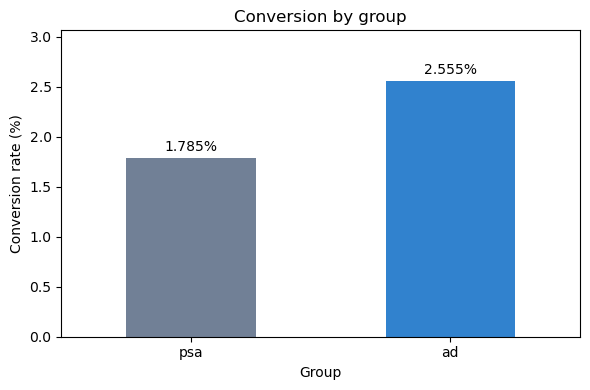

In [5]:
ax = (summary["conversion_rate"] * 100).plot.bar(
    color=["#718096", "#3182ce"], rot=0, figsize=(6, 4))
ax.set(xlabel="Group", ylabel="Conversion rate (%)", title="Conversion by group")
ax.bar_label(ax.containers[0], fmt="%.3f%%", padding=3)
ax.set_ylim(0, summary["conversion_rate"].max() * 120)
plt.tight_layout()
plt.show()

## Statistical comparison

A two-sided pooled two-proportion z-test tests equal conversion rates. The 95% confidence interval uses the unpooled standard error and normal approximation. The test assumes independent observations.

In [6]:
n_control, n_ad = summary.loc["psa", "users"], summary.loc["ad", "users"]
x_control, x_ad = summary.loc["psa", "conversions"], summary.loc["ad", "conversions"]
pooled = (x_control + x_ad) / (n_control + n_ad)
se_null = np.sqrt(pooled * (1 - pooled) * (1 / n_control + 1 / n_ad))
if se_null == 0:
    raise ValueError("Zero pooled standard error; z-test is undefined")
z = difference / se_null
p_value = 2 * norm.sf(abs(z))
se_diff = np.sqrt(p_control * (1 - p_control) / n_control + p_ad * (1 - p_ad) / n_ad)
ci_low, ci_high = difference + np.array([-1, 1]) * norm.ppf(0.975) * se_diff
print(f"z = {z:.3f}; two-sided p = {p_value:.3g}")
print(f"95% CI for difference: [{ci_low * 100:.3f}, {ci_high * 100:.3f}] percentage points")

z = 7.370; two-sided p = 1.71e-13
95% CI for difference: [0.595, 0.943] percentage points


## Interpretation and conclusion

The observed ad conversion rate is 2.555%, compared with 1.785% for PSA: a difference of 0.769 percentage points, or a 43.09% relative lift over the PSA rate. These describe the same comparison on different scales. The 95% confidence interval of 0.595 to 0.943 percentage points describes the range of differences compatible with this method and data; over repeated comparable samples, the procedure would cover the true difference 95% of the time.

The two-sided p-value is approximately 1.71e-13, below the 5% threshold: the data provide evidence against equal conversion rates under the test assumptions. A small p-value does not measure business value or establish a causal effect. In particular, assignment and independence are not established by the CSV, and uncertainty about design and data collection is not captured by the interval.

**Decision:** the observed difference merits further investigation, but the data alone do not justify a rollout or a profit claim. Before deciding, verify randomization, allocation, eligibility, timing and conversion definitions, then compare the cost of advertising against the value of conversions. Exposure variables may be post-assignment and are not used for causal subgroup claims. This is one overall comparison with no multiple-testing correction.